In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [15]:
class NavierStokesPINN(nn.Module):
    def __init__(self, in_features=2, num_layers=9, num_hidden=160, out_features=2):
        super().__init__()
        layers = [nn.Linear(in_features, num_hidden), nn.SiLU()]
        
        for _ in range(num_layers - 1):
            layers.append(nn.Linear(num_hidden, num_hidden))
            layers.append(nn.SiLU())
            
        layers.append(nn.Linear(num_hidden, out_features))
        self.net = nn.Sequential(*layers)

        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)


    def forward(self, input_para):
        # If input is a list/tuple of tensors [x, y, t], concatenate to (N, in_features)
        if isinstance(input_para, (list, tuple)):
            xy = torch.cat(input_para, dim=1)
        else:
            xy = input_para
            
        # Ensure it is a Tensor before hitting nn.Linear
        return self.net(xy)

In [16]:

# ----------------------------------------------------------------------------
# Geometric sampling section (same as before, corners belong to the walls)
# ----------------------------------------------------------------------------
N = 70

# geometric sampling section
x = torch.linspace(0.0, 1.0, N)
y = torch.linspace(0.0, 1.0, N)
X, Y = torch.meshgrid(x, y, indexing="ij")
xy_all = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=1)
 
mask_b_c = ((Y == 0) | (Y == 1)).reshape(-1)
mask_inlet = (((X == 0) | (X == 1)) & (Y > 0) & (Y < 1)).reshape(-1)
 
xy_bnd_bc = xy_all[mask_b_c].to(device)                    # walls (y*=0,1)
xy_bnd_inlet = xy_all[mask_inlet].to(device)               # x*=0 and x*=1 edges
xy_int = xy_all[~(mask_b_c | mask_inlet)].to(device).requires_grad_(True)
 
# Split inlet / outlet
xy_in = xy_bnd_inlet[xy_bnd_inlet[:, 0] == 0.0]
xy_out = xy_bnd_inlet[xy_bnd_inlet[:, 0] == 1.0]

def grad(f, xy):
    """Gradient of scalar field f (N,1) w.r.t. xy (N,2) -> (N,2): [d/dx*, d/dy*]"""
    return torch.autograd.grad(f, xy, grad_outputs=torch.ones_like(f),
                               create_graph=True)[0]
"""
Non-dimensional Hagen-Poiseuille flow between plates (PINN loss section)
 
Scales:
    x* = x/x0,  y* = y/h
    u* = u/u0,  u0 = 1 (arbirtary)
    p* = p h^2 / (mu u0 x0)
 
Network: (x*, y*) -> (u*, p*)
 
Non-dimensional equations (v = 0, fully developed):
    continuity   : du*/dx*                      = 0
    x-momentum   : dp*/dx* - d2u*/dy*2          = 0
    y-momentum   : dp*/dy*                      = 0
 
"""
# ----------------------------------------------------------------------------
# Loss section
# ----------------------------------------------------------------------------

P_IN = 0.0                # p* at x* = 0
P_OUT = -2.0              # p* at x* = 1  (free choice: sets the flow strength)
  # resulting dp*/dx* (negative = flow in +x)
 
 
def pde_loss(model, xy):
    out = model(xy)
    u, p = out[:, 0:1], out[:, 1:2]
 
    du = grad(u, xy)
    u_x, u_y = du[:, 0:1], du[:, 1:2]
    u_yy = grad(u_y, xy)[:, 1:2]
    
    dp = grad(p, xy)
    p_x, p_y = dp[:, 0:1], dp[:, 1:2]
    p_xx = grad(p_x,xy)[:,0:1]
 
    res_cont = u_x               # continuity: du*/dx* = 0
    res_momx = p_x - u_yy        # x-momentum: dp*/dx* = d2u*/dy*2
    res_momy = p_y               # y-momentum: dp*/dy* = 0
    res_constP = p_xx
    return (torch.mean(res_cont ** 2),
            torch.mean(res_momx ** 2),
            torch.mean(res_momy ** 2),
            torch.mean(res_constP**2))
 
 
def bc_loss(model):
    # No-slip on the walls: u* = 0
    loss_wall = torch.mean(model(xy_bnd_bc)[:, 0:1] ** 2)
    # Pressure fixed at inlet and outlet (drives the flow)
    loss_pin = torch.mean((model(xy_in)[:, 1:2] - P_IN) ** 2)
    loss_pout = torch.mean((model(xy_out)[:, 1:2] - P_OUT) ** 2)
    return loss_wall, loss_pin + loss_pout
 
 
W = dict(cont=1.0, momx=1.0, momy=1.0,constP=1, wall=10.0, pres=10.0)
 
 
def total_loss(model):
    l_c, l_mx, l_my ,l_cp = pde_loss(model, xy_int)
    l_wall, l_pres = bc_loss(model)
    loss = (W["cont"] * l_c + W["momx"] * l_mx + W["momy"] * l_my
            + W["wall"] * l_wall + W["pres"] * l_pres + W["constP"]*l_cp)
    return loss, dict(cont=l_c.item(), momx=l_mx.item(), momy=l_my.item(),
                      wall=l_wall.item(), pres=l_pres.item(),constP=l_cp.item())
 


[Adam      0] loss=3.999e+00 | cont=2.5e-08 momx=1.2e-07 momy=1.0e-09 constP=4.1e-10 wall=4.5e-08 pres=4.0e+00 | 2s
             lr=2.00e-03
[Adam    200] loss=5.532e-02 | cont=2.4e-03 momx=2.4e-02 momy=1.3e-03 constP=2.5e-03 wall=1.2e-02 pres=1.3e-02 | 330s
             lr=2.00e-03

Unweighted loss < 1e-04 at epoch 293: switching to L-BFGS
[L-BFGS round      0] loss=8.924e-07 | cont=9.5e-08 momx=7.0e-07 momy=3.7e-08 constP=5.7e-08 wall=1.1e-09 pres=1.2e-09 | 689s
[L-BFGS round      1] loss=8.924e-07 | cont=9.5e-08 momx=7.0e-07 momy=3.7e-08 constP=5.7e-08 wall=1.1e-09 pres=1.2e-09 | 704s
[L-BFGS round      2] loss=8.924e-07 | cont=9.5e-08 momx=7.0e-07 momy=3.7e-08 constP=5.7e-08 wall=1.1e-09 pres=1.2e-09 | 712s
[L-BFGS round      3] loss=8.924e-07 | cont=9.5e-08 momx=7.0e-07 momy=3.7e-08 constP=5.7e-08 wall=1.1e-09 pres=1.2e-09 | 719s

Final unweighted loss = 8.924e-07
Terms: cont=9.50e-08 momx=7.01e-07 momy=3.74e-08 constP=5.71e-08 wall=1.11e-09 pres=1.24e-09


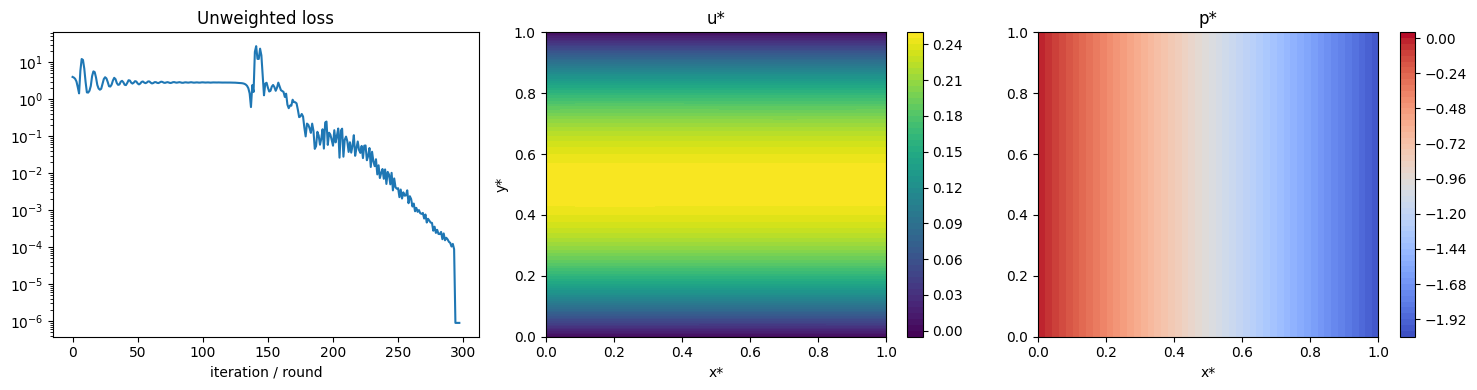

In [ ]:
# ----------------------------------------------------------------------------
# Training loop (data-free: only PDE residuals + boundary conditions)
# Paste below your sampling section, NavierStokesPINN class and loss section.
# Needs: NavierStokesPINN, pde_loss, bc_loss, W, xy_int, xy_all, X, Y, device
# ----------------------------------------------------------------------------
import time
import copy
import numpy as np
import matplotlib.pyplot as plt

model = NavierStokesPINN(in_features=2, num_layers=9, num_hidden=160,
                         out_features=2).to(device)

# ---- settings ---------------------------------------------------------------
ADAM_LR = 2e-3          # initial learning rate
MIN_LR = 1e-6           # Adam stops decaying / hands over at this LR
LR_FACTOR = 0.5         # LR is multiplied by this on every plateau
LR_PATIENCE = 200       # epochs without improvement before decaying the LR
SWITCH_LOSS = 1e-4      # switch Adam -> L-BFGS once unweighted loss is below this
MAX_ADAM = 20000        # hard cap on Adam epochs
LBFGS_ROUNDS = 20       # max outer L-BFGS rounds
LBFGS_ITERS = 200       # inner iterations per round
TOL = 1e-10             # stop completely once unweighted loss is below this
LOG_EVERY = 200


# ---- losses -----------------------------------------------------------------
def compute_losses(model):
    """
    weighted   : used ONLY for backprop / optimisation (uses W)
    plain      : unweighted sum of all terms, used for monitoring, LR
                 scheduling, best-model selection and the Adam->L-BFGS switch
    parts      : individual unweighted terms
    """
    l_c, l_mx, l_my, l_cp = pde_loss(model, xy_int)
    l_wall, l_pres = bc_loss(model)
    weighted = (W["cont"] * l_c + W["momx"] * l_mx + W["momy"] * l_my
                + W["constP"] * l_cp + W["wall"] * l_wall + W["pres"] * l_pres)
    plain = l_c + l_mx + l_my + l_cp + l_wall + l_pres
    parts = dict(cont=l_c.item(), momx=l_mx.item(), momy=l_my.item(),
                 constP=l_cp.item(), wall=l_wall.item(), pres=l_pres.item())
    return weighted, plain, parts


history = []                       # unweighted loss history
best_loss, best_state = float("inf"), None


def log(tag, it, plain, parts, t0):
    print(f"[{tag} {it:6d}] loss={plain:.3e} | "
          + " ".join(f"{k}={v:.1e}" for k, v in parts.items())
          + f" | {time.time() - t0:.0f}s")


# ---- Stage 1: Adam with plateau-based LR reduction ---------------------------
optimizer = torch.optim.Adam(model.parameters(), lr=ADAM_LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=LR_FACTOR, patience=LR_PATIENCE,
    min_lr=MIN_LR)

t0 = time.time()
for ep in range(MAX_ADAM + 1):
    optimizer.zero_grad()
    weighted, plain, parts = compute_losses(model)
    weighted.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
    optimizer.step()

    plain_val = plain.item()
    history.append(plain_val)
    scheduler.step(plain_val)                  # LR decays on unweighted loss

    if plain_val < best_loss:
        best_loss, best_state = plain_val, copy.deepcopy(model.state_dict())

    if ep % LOG_EVERY == 0:
        log("Adam", ep, plain_val, parts, t0)
        print(f"             lr={optimizer.param_groups[0]['lr']:.2e}")

    if plain_val < SWITCH_LOSS:
        print(f"\nUnweighted loss < {SWITCH_LOSS:.0e} at epoch {ep}: "
              f"switching to L-BFGS")
        break
    if optimizer.param_groups[0]["lr"] <= MIN_LR * 1.0001 and ep > LR_PATIENCE:
        print(f"\nLR reached minimum at epoch {ep}: switching to L-BFGS")
        break

# ---- Stage 2: L-BFGS in rounds, restarted from the best weights --------------
model.load_state_dict(best_state)
stall = 0
for rnd in range(LBFGS_ROUNDS):
    lbfgs = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=LBFGS_ITERS,
                              tolerance_grad=1e-14, tolerance_change=1e-16,
                              history_size=50, line_search_fn="strong_wolfe")

    def closure():
        lbfgs.zero_grad()
        weighted, _, _ = compute_losses(model)
        weighted.backward()
        return weighted

    lbfgs.step(closure)

    _, plain, parts = compute_losses(model)
    plain_val = plain.item()
    history.append(plain_val)
    log("L-BFGS round", rnd, plain_val, parts, t0)

    if plain_val < best_loss:
        stall = stall + 1 if plain_val > 0.99 * best_loss else 0
        best_loss, best_state = plain_val, copy.deepcopy(model.state_dict())
    else:
        stall += 1
        model.load_state_dict(best_state)      # discard a worse round

    if best_loss < TOL or stall >= 3:
        break

model.load_state_dict(best_state)
_, plain, parts = compute_losses(model)
print(f"\nFinal unweighted loss = {plain.item():.3e}")
print("Terms:", " ".join(f"{k}={v:.2e}" for k, v in parts.items()))

# ---- Results (no reference solution used) ------------------------------------
model.eval()
with torch.no_grad():
    out = model(xy_all.to(device)).cpu().numpy()
n = int(np.sqrt(xy_all.shape[0]))
U = out[:, 0].reshape(n, n)
P = out[:, 1].reshape(n, n)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].semilogy(history)
ax[0].set_title("Unweighted loss"); ax[0].set_xlabel("iteration / round")
c1 = ax[1].contourf(X.numpy(), Y.numpy(), U, 50, cmap="viridis")
ax[1].set_title("u*"); ax[1].set_xlabel("x*"); ax[1].set_ylabel("y*")
fig.colorbar(c1, ax=ax[1])
c2 = ax[2].contourf(X.numpy(), Y.numpy(), P, 50, cmap="coolwarm")
ax[2].set_title("p*"); ax[2].set_xlabel("x*")
fig.colorbar(c2, ax=ax[2])
plt.tight_layout()
plt.savefig("pinn_results.png", dpi=150)
plt.show()

torch.save(best_state, "pinn_poiseuille.pt")


In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Training with Tanh
class NavierStokesPINNTANH(nn.Module):
    def __init__(self, in_features=2, num_layers=9, num_hidden=160, out_features=2):
        super().__init__()
        layers = [nn.Linear(in_features, num_hidden), nn.Tanh()]
        
        for _ in range(num_layers - 1):
            layers.append(nn.Linear(num_hidden, num_hidden))
            layers.append(nn.Tanh())
            
        layers.append(nn.Linear(num_hidden, out_features))
        self.net = nn.Sequential(*layers)

        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)


    def forward(self, input_para):
        # If input is a list/tuple of tensors [x, y, t], concatenate to (N, in_features)
        if isinstance(input_para, (list, tuple)):
            xy = torch.cat(input_para, dim=1)
        else:
            xy = input_para
            
        # Ensure it is a Tensor before hitting nn.Linear
        return self.net(xy)

In [ ]:

# ----------------------------------------------------------------------------
# Geometric sampling section (same as before, corners belong to the walls)
# ----------------------------------------------------------------------------
N = 70

# geometric sampling section
x = torch.linspace(0.0, 1.0, N)
y = torch.linspace(0.0, 1.0, N)
X, Y = torch.meshgrid(x, y, indexing="ij")
xy_all = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=1)
 
mask_b_c = ((Y == 0) | (Y == 1)).reshape(-1)
mask_inlet = (((X == 0) | (X == 1)) & (Y > 0) & (Y < 1)).reshape(-1)
 
xy_bnd_bc = xy_all[mask_b_c].to(device)                    # walls (y*=0,1)
xy_bnd_inlet = xy_all[mask_inlet].to(device)               # x*=0 and x*=1 edges
xy_int = xy_all[~(mask_b_c | mask_inlet)].to(device).requires_grad_(True)
 
# Split inlet / outlet
xy_in = xy_bnd_inlet[xy_bnd_inlet[:, 0] == 0.0]
xy_out = xy_bnd_inlet[xy_bnd_inlet[:, 0] == 1.0]

def grad(f, xy):
    """Gradient of scalar field f (N,1) w.r.t. xy (N,2) -> (N,2): [d/dx*, d/dy*]"""
    return torch.autograd.grad(f, xy, grad_outputs=torch.ones_like(f),
                               create_graph=True)[0]
"""
Non-dimensional Hagen-Poiseuille flow between plates (PINN loss section)
 
Scales:
    x* = x/x0,  y* = y/h
    u* = u/u0,  u0 = 1 (arbirtary)
    p* = p h^2 / (mu u0 x0)
 
Network: (x*, y*) -> (u*, p*)
 
Non-dimensional equations (v = 0, fully developed):
    continuity   : du*/dx*                      = 0
    x-momentum   : dp*/dx* - d2u*/dy*2          = 0
    y-momentum   : dp*/dy*                      = 0
 
"""
# ----------------------------------------------------------------------------
# Loss section
# ----------------------------------------------------------------------------

P_IN = 0.0                # p* at x* = 0
P_OUT = -2.0              # p* at x* = 1  (free choice: sets the flow strength)
  # resulting dp*/dx* (negative = flow in +x)
 
 
def pde_loss(model, xy):
    out = model(xy)
    u, p = out[:, 0:1], out[:, 1:2]
 
    du = grad(u, xy)
    u_x, u_y = du[:, 0:1], du[:, 1:2]
    u_yy = grad(u_y, xy)[:, 1:2]
    
    dp = grad(p, xy)
    p_x, p_y = dp[:, 0:1], dp[:, 1:2]
    p_xx = grad(p_x,xy)[:,0:1]
 
    res_cont = u_x               # continuity: du*/dx* = 0
    res_momx = p_x - u_yy        # x-momentum: dp*/dx* = d2u*/dy*2
    res_momy = p_y               # y-momentum: dp*/dy* = 0
    res_constP = p_xx
    return (torch.mean(res_cont ** 2),
            torch.mean(res_momx ** 2),
            torch.mean(res_momy ** 2),
            torch.mean(res_constP**2))
 
 
def bc_loss(model):
    # No-slip on the walls: u* = 0
    loss_wall = torch.mean(model(xy_bnd_bc)[:, 0:1] ** 2)
    # Pressure fixed at inlet and outlet (drives the flow)
    loss_pin = torch.mean((model(xy_in)[:, 1:2] - P_IN) ** 2)
    loss_pout = torch.mean((model(xy_out)[:, 1:2] - P_OUT) ** 2)
    return loss_wall, loss_pin + loss_pout
 
 
W = dict(cont=1.0, momx=1.0, momy=1.0,constP=1, wall=10.0, pres=10.0)
 
 
def total_loss(model):
    l_c, l_mx, l_my ,l_cp = pde_loss(model, xy_int)
    l_wall, l_pres = bc_loss(model)
    loss = (W["cont"] * l_c + W["momx"] * l_mx + W["momy"] * l_my
            + W["wall"] * l_wall + W["pres"] * l_pres + W["constP"]*l_cp)
    return loss, dict(cont=l_c.item(), momx=l_mx.item(), momy=l_my.item(),
                      wall=l_wall.item(), pres=l_pres.item(),constP=l_cp.item())
 


In [ ]:
# ----------------------------------------------------------------------------
# Training loop (data-free: only PDE residuals + boundary conditions)
# Paste below your sampling section, NavierStokesPINN class and loss section.
# Needs: NavierStokesPINN, pde_loss, bc_loss, W, xy_int, xy_all, X, Y, device
# ----------------------------------------------------------------------------
import time
import copy
import numpy as np
import matplotlib.pyplot as plt

model = NavierStokesPINNTANH(in_features=2, num_layers=9, num_hidden=160,
                         out_features=2).to(device)

# ---- settings ---------------------------------------------------------------
ADAM_LR = 2e-3          # initial learning rate
MIN_LR = 1e-6           # Adam stops decaying / hands over at this LR
LR_FACTOR = 0.5         # LR is multiplied by this on every plateau
LR_PATIENCE = 200       # epochs without improvement before decaying the LR
SWITCH_LOSS = 1e-4      # switch Adam -> L-BFGS once unweighted loss is below this
MAX_ADAM = 20000        # hard cap on Adam epochs
LBFGS_ROUNDS = 20       # max outer L-BFGS rounds
LBFGS_ITERS = 200       # inner iterations per round
TOL = 1e-10             # stop completely once unweighted loss is below this
LOG_EVERY = 200


# ---- losses -----------------------------------------------------------------
def compute_losses(model):
    """
    weighted   : used ONLY for backprop / optimisation (uses W)
    plain      : unweighted sum of all terms, used for monitoring, LR
                 scheduling, best-model selection and the Adam->L-BFGS switch
    parts      : individual unweighted terms
    """
    l_c, l_mx, l_my, l_cp = pde_loss(model, xy_int)
    l_wall, l_pres = bc_loss(model)
    weighted = (W["cont"] * l_c + W["momx"] * l_mx + W["momy"] * l_my
                + W["constP"] * l_cp + W["wall"] * l_wall + W["pres"] * l_pres)
    plain = l_c + l_mx + l_my + l_cp + l_wall + l_pres
    parts = dict(cont=l_c.item(), momx=l_mx.item(), momy=l_my.item(),
                 constP=l_cp.item(), wall=l_wall.item(), pres=l_pres.item())
    return weighted, plain, parts


history = []                       # unweighted loss history
best_loss, best_state = float("inf"), None


def log(tag, it, plain, parts, t0):
    print(f"[{tag} {it:6d}] loss={plain:.3e} | "
          + " ".join(f"{k}={v:.1e}" for k, v in parts.items())
          + f" | {time.time() - t0:.0f}s")


# ---- Stage 1: Adam with plateau-based LR reduction ---------------------------
optimizer = torch.optim.Adam(model.parameters(), lr=ADAM_LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=LR_FACTOR, patience=LR_PATIENCE,
    min_lr=MIN_LR)

t0 = time.time()
for ep in range(MAX_ADAM + 1):
    optimizer.zero_grad()
    weighted, plain, parts = compute_losses(model)
    weighted.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
    optimizer.step()

    plain_val = plain.item()
    history.append(plain_val)
    scheduler.step(plain_val)                  # LR decays on unweighted loss

    if plain_val < best_loss:
        best_loss, best_state = plain_val, copy.deepcopy(model.state_dict())

    if ep % LOG_EVERY == 0:
        log("Adam", ep, plain_val, parts, t0)
        print(f"             lr={optimizer.param_groups[0]['lr']:.2e}")

    if plain_val < SWITCH_LOSS:
        print(f"\nUnweighted loss < {SWITCH_LOSS:.0e} at epoch {ep}: "
              f"switching to L-BFGS")
        break
    if optimizer.param_groups[0]["lr"] <= MIN_LR * 1.0001 and ep > LR_PATIENCE:
        print(f"\nLR reached minimum at epoch {ep}: switching to L-BFGS")
        break

# ---- Stage 2: L-BFGS in rounds, restarted from the best weights --------------
model.load_state_dict(best_state)
stall = 0
for rnd in range(LBFGS_ROUNDS):
    lbfgs = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=LBFGS_ITERS,
                              tolerance_grad=1e-14, tolerance_change=1e-16,
                              history_size=50, line_search_fn="strong_wolfe")

    def closure():
        lbfgs.zero_grad()
        weighted, _, _ = compute_losses(model)
        weighted.backward()
        return weighted

    lbfgs.step(closure)

    _, plain, parts = compute_losses(model)
    plain_val = plain.item()
    history.append(plain_val)
    log("L-BFGS round", rnd, plain_val, parts, t0)

    if plain_val < best_loss:
        stall = stall + 1 if plain_val > 0.99 * best_loss else 0
        best_loss, best_state = plain_val, copy.deepcopy(model.state_dict())
    else:
        stall += 1
        model.load_state_dict(best_state)      # discard a worse round

    if best_loss < TOL or stall >= 3:
        break

model.load_state_dict(best_state)
_, plain, parts = compute_losses(model)
print(f"\nFinal unweighted loss = {plain.item():.3e}")
print("Terms:", " ".join(f"{k}={v:.2e}" for k, v in parts.items()))

# ---- Results (no reference solution used) ------------------------------------
model.eval()
with torch.no_grad():
    out = model(xy_all.to(device)).cpu().numpy()
n = int(np.sqrt(xy_all.shape[0]))
U = out[:, 0].reshape(n, n)
P = out[:, 1].reshape(n, n)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].semilogy(history)
ax[0].set_title("Unweighted loss"); ax[0].set_xlabel("iteration / round")
c1 = ax[1].contourf(X.numpy(), Y.numpy(), U, 50, cmap="viridis")
ax[1].set_title("u*"); ax[1].set_xlabel("x*"); ax[1].set_ylabel("y*")
fig.colorbar(c1, ax=ax[1])
c2 = ax[2].contourf(X.numpy(), Y.numpy(), P, 50, cmap="coolwarm")
ax[2].set_title("p*"); ax[2].set_xlabel("x*")
fig.colorbar(c2, ax=ax[2])
plt.tight_layout()
plt.savefig("pinn_results.png", dpi=150)
plt.show()

torch.save(best_state, "pinn_poiseuille.pt")


NameError: name 'NavierStokesPINN' is not defined